In [2]:
# installing the neccessairy librairies for the analysis

In [16]:
# import the librairies

In [2]:
import pandas as pd
import numpy as np

In [3]:
import sys
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn
import statsmodels.api as sm
import openpyxl


print("Python path:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Installation successful!")

Python path: C:\Users\IBOU\.conda\envs\notebook-env\python.exe
Python version: 3.14.8
Pandas: 3.0.6
NumPy: 2.5.4
Installation successful!


In [4]:
# This data is download from Humanitarian Data Exchange ( HDX ) Under OCHA

In [5]:
# Data source : NER Situation désagrégée au 29 Septembre 2025.csv
#Situation des inondations au Niger et réponses apportées - Novembre 2025

In [6]:
# Project Roadmap
# Step 1 — Load and understand the data
# Step 2 — Data quality assessment : Missing values, duplicates, data types, unusual values and administrative codes.
# Step 3 — Descriptive analysis : Affected people, households, housing damage, agricultural losses and regional comparisons.
# Step 4 — Visualizations : Create professional charts in Python.
# Step 5 — MEAL interpretation and dashboard:Identify priority locations using transparent criteria, write recommendations and prepare for Power BI.




In [12]:
# Techarger la base des donnees sur python
# Step 1 — Load and understand the data

In [8]:
df = pd.read_csv("C://Users//IBOU//OneDrive - Good Neighbors Global Partnership Center//Desktop//Niger_Flood_Impact_Analysis//ner-situation-desagregee-au-29-septembre-2025.csv",encoding="cp1252" )

In [9]:
%pip install fsspec

Note: you may need to restart the kernel to use updated packages.


In [13]:
import fsspec

In [11]:
# let's display the first 10 r0ws of our dataset
df.head(10)

,ISO3,Pcode1,Région,Pcode2,Département,Ménages sinistrés,Personnes sinistrées,Maisons effondrées,Cases endommagées,Pertes en vie humaine par Noyade,...,Greniers,Vivre (Tonne),Puits effondrés,Puits ensevelis,Forages endommagés,Lieu de culte,Centre de santé,Classe,Route,pont endommagé
0,NER,NE001,Agadez,NER001001,Aderbissinat,116,739,51,0,0,...,0,0,0,0,0,0,0,0,0.0,0
1,NER,NE001,Agadez,NER001002,Arlit,424,3016,420,0,0,...,0,0,0,0,0,0,0,0,0.0,0
2,NER,NE001,Agadez,NER001003,Bilma,579,3059,460,0,0,...,0,0,0,0,0,7,0,0,0.0,0
3,NER,NE001,Agadez,NER001004,Iferouane,100,512,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0
4,NER,NE001,Agadez,NER001005,Ingall,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0
5,NER,NE001,Agadez,NER001005,Ingall,35,320,8,0,0,...,0,0,0,0,0,0,0,0,0.0,0
6,NER,NE001,Agadez,NER001006,Tchirozerine,1111,7347,781,158,5,...,0,0,4,14,0,0,0,0,0.0,0
7,NER,NE002,Diffa,NER002002,Diffa,936,6243,847,88,0,...,0,0,0,0,0,0,0,0,0.0,0
8,NER,NE002,Diffa,NER002003,Goudoumaria,1,3,1,0,0,...,0,0,0,0,0,0,0,0,NaN,0
9,NER,NE002,Diffa,NER002004,Maïné Soroa,488,3678,503,12,0,...,0,0,0,0,0,0,0,0,0.0,0


In [16]:
# Step 1.3: Inspect the structure of the data
# voir la structure des donnees

print("Number of rows and columns ou nbr des colonnes:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns ou nbr des colonnes:
(62, 30)

First 5 rows:


,ISO3,Pcode1,Région,Pcode2,Département,Ménages sinistrés,Personnes sinistrées,Maisons effondrées,Cases endommagées,Pertes en vie humaine par Noyade,...,Greniers,Vivre (Tonne),Puits effondrés,Puits ensevelis,Forages endommagés,Lieu de culte,Centre de santé,Classe,Route,pont endommagé
0,NER,NE001,Agadez,NER001001,Aderbissinat,116,739,51,0,0,...,0,0,0,0,0,0,0,0,0.0,0
1,NER,NE001,Agadez,NER001002,Arlit,424,3016,420,0,0,...,0,0,0,0,0,0,0,0,0.0,0
2,NER,NE001,Agadez,NER001003,Bilma,579,3059,460,0,0,...,0,0,0,0,0,7,0,0,0.0,0
3,NER,NE001,Agadez,NER001004,Iferouane,100,512,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0
4,NER,NE001,Agadez,NER001005,Ingall,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0



Column names:
['ISO3', 'Pcode1', 'Région', 'Pcode2', 'Département', ' Ménages sinistrés', ' Personnes sinistrées', ' Maisons effondrées', ' Cases endommagées', ' Pertes en vie humaine par Noyade', ' Pertes en vie humaine par Effond', ' Pertes en vie humaine par Foudre', " Perte d'animaux par Petits ruminants", " Perte d'animaux par Gros ruminant", ' Aires de cultures inondées  /ha', ' Latrines', ' Mur', ' Hangars', ' Magasins', ' Boutiques', ' Greniers', ' Vivre (Tonne)', ' Puits effondrés', ' Puits ensevelis', ' Forages endommagés ', ' Lieu de culte', ' Centre de santé', ' Classe', ' Route', ' pont endommagé ']


In [17]:
# Nous avons 62 lignes et 30 colonnes dans notre base des donnes

In [18]:
# Step 1.4: Examine column types and non-missing values ( les types de colonnes et les donnees manquantes)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   ISO3                                   62 non-null     str    
 1   Pcode1                                 62 non-null     str    
 2   Région                                 62 non-null     str    
 3   Pcode2                                 62 non-null     str    
 4   Département                            62 non-null     str    
 5    Ménages sinistrés                     62 non-null     int64  
 6    Personnes sinistrées                  62 non-null     int64  
 7    Maisons effondrées                    62 non-null     int64  
 8    Cases endommagées                     62 non-null     int64  
 9    Pertes en vie humaine par Noyade      62 non-null     int64  
 10   Pertes en vie humaine par Effond      62 non-null     int64  
 11   Pertes en vie huma

In [19]:
# la majorite des nos varriable sont des numeric

In [20]:
# Confirm the number of records and variables
rows, columns = df.shape

print(f"Number of records: {rows}")
print(f"Number of variables: {columns}")

# Basic verification
assert rows == 62, "Check the number of rows"
assert columns == 30, "Check the number of columns"

print("Step 1 verification passed!")

Number of records: 62
Number of variables: 30
Step 1 verification passed!


In [21]:
# Step2  Data quality assessement

In [22]:
# Count variables by data type
print(df.dtypes.value_counts())

# Display each variable and its data type
display(
    pd.DataFrame({
        "Variable": df.columns,
        "Data type": df.dtypes.astype(str).values,
        "Missing values": df.isna().sum().values
    })
)

int64      23
str         5
float64     2
Name: count, dtype: int64


,Variable,Data type,Missing values
0,ISO3,str,0
1,Pcode1,str,0
2,Région,str,0
3,Pcode2,str,0
4,Département,str,0
5,Ménages sinistrés,int64,0
6,Personnes sinistrées,int64,0
7,Maisons effondrées,int64,0
8,Cases endommagées,int64,0
9,Pertes en vie humaine par Noyade,int64,0


In [23]:
# Inspect administrative regions and departments
print("Regions:")
print(df["Région"].value_counts(dropna=False))

print("\nNumber of unique regions:")
print(df["Région"].nunique())

print("\nNumber of unique department codes:");
]=
]\

print(df["Pcode2"].nunique())

print("\nRepeated department codes:")
print(
    df.loc[df["Pcode2"].duplicated(keep=False),
           ["Région", "Département", "Pcode2"]]
      .sort_values("Pcode2")
)

Regions:
Région
Tillabéri    12
Tahoua       11
Zinder       10
Maradi        9
Dosso         8
Agadez        7
Diffa         4
Niamey        1
Name: count, dtype: int64

Number of unique regions:
8

Number of unique department codes:
57

Repeated department codes:
    Région Département     Pcode2
4   Agadez      Ingall  NER001005
5   Agadez      Ingall  NER001005
29  Tahoua      Abalak  NER005001
30  Tahoua      Abalak  NER005001
34  Tahoua       Keita  NER005006
35  Tahoua       Keita  NER005006
36  Tahoua     Madaoua  NER005007
37  Tahoua     Madaoua  NER005007
58  Zinder     Takeita  NER007008
59  Zinder     Takeita  NER007008


In [24]:
# STEP 2.1: Check missing values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (missing_values / len(df) * 100).round(2)
})

# Display only columns that have missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

if missing_summary.empty:
    print("No missing values found in the dataset.")
else:
    display(missing_summary)

print("\nTotal missing cells:", df.isnull().sum().sum())

,Missing_Count,Missing_Percentage
Route,1,1.61



Total missing cells: 1


In [25]:
# STEP 2.2: Check exact duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    print("\nDuplicate records:")
    display(df[df.duplicated(keep=False)].sort_values(
        by="Région"
    ))
else:
    print("No exact duplicate rows found.")

Number of exact duplicate rows: 0
No exact duplicate rows found.


In [26]:
# STEP 2.3: Inspect data types

dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": df.nunique(dropna=True).values
})

display(dtype_summary) 

,Column,Data_Type,Unique_Values
0,ISO3,str,1
1,Pcode1,str,8
2,Région,str,8
3,Pcode2,str,57
4,Département,str,57
5,Ménages sinistrés,int64,59
6,Personnes sinistrées,int64,61
7,Maisons effondrées,int64,57
8,Cases endommagées,int64,27
9,Pertes en vie humaine par Noyade,int64,4


In [27]:
# STEP 2.4: Inspect numerical columns

numeric_df = df.select_dtypes(include="number")

display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Ménages sinistrés,62.0,986.774194,1526.359791,1.0,113.00,513.5,1101.50,8474.0
Personnes sinistrées,62.0,7640.870968,13473.173931,0.0,780.75,3801.0,8139.75,88107.0
Maisons effondrées,62.0,749.193548,1406.683961,0.0,53.50,352.0,607.25,8023.0
Cases endommagées,62.0,31.838710,82.825353,0.0,0.00,0.0,23.75,571.0
Pertes en vie humaine par Noyade,62.0,0.338710,0.828658,0.0,0.00,0.0,0.00,5.0
Pertes en vie humaine par Effond,62.0,1.580645,3.170294,0.0,0.00,0.0,1.75,14.0
Pertes en vie humaine par Foudre,62.0,0.064516,0.306806,0.0,0.00,0.0,0.00,2.0
Perte d'animaux par Petits ruminants,62.0,8.209677,25.842611,0.0,0.00,0.0,0.00,144.0
Perte d'animaux par Gros ruminant,62.0,0.241935,1.081673,0.0,0.00,0.0,0.00,7.0
Aires de cultures inondées /ha,62.0,143.176290,377.376500,0.0,0.00,0.0,19.25,2053.0


In [28]:
# Step 3 — Exploratory Data Analysis

In [30]:
# STEP 3.1: Identify key flood impact indicators

key_columns = [
    "Région",
    "Département",
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Aires de cultures inondées  /ha"
]

# Display only columns that exist in the dataset
available_columns = [
    col for col in key_columns if col in df.columns
]

display(df[available_columns].head(15))

,Région,Département
0,Agadez,Aderbissinat
1,Agadez,Arlit
2,Agadez,Bilma
3,Agadez,Iferouane
4,Agadez,Ingall
5,Agadez,Ingall
6,Agadez,Tchirozerine
7,Diffa,Diffa
8,Diffa,Goudoumaria
9,Diffa,Maïné Soroa


In [32]:
# STEP 3.2: Descriptive statistics for numeric indicators

numeric_columns = [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Aires de cultures inondées  /ha"
]

available_numeric_columns = [
    col for col in numeric_columns
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

display(df[available_numeric_columns].describe().T.round(2))

ValueError: Cannot describe a DataFrame without columns

In [33]:
# STEP 3: Diagnose the error

print("Available column names:")
for col in df.columns:
    print(repr(col))

print("\nData types of the impact indicators:")
for col in [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Aires de cultures inondées  /ha"
]:
    if col in df.columns:
        print(f"{col}: {df[col].dtype}")
    else:
        print(f"{col}: NOT FOUND")

Available column names:
'ISO3'
'Pcode1'
'Région'
'Pcode2'
'Département'
' Ménages sinistrés'
' Personnes sinistrées'
' Maisons effondrées'
' Cases endommagées'
' Pertes en vie humaine par Noyade'
' Pertes en vie humaine par Effond'
' Pertes en vie humaine par Foudre'
" Perte d'animaux par Petits ruminants"
" Perte d'animaux par Gros ruminant"
' Aires de cultures inondées  /ha'
' Latrines'
' Mur'
' Hangars'
' Magasins'
' Boutiques'
' Greniers'
' Vivre (Tonne)'
' Puits effondrés'
' Puits ensevelis'
' Forages endommagés '
' Lieu de culte'
' Centre de santé'
' Classe'
' Route'
' pont endommagé '

Data types of the impact indicators:
Ménages sinistrés: NOT FOUND
Personnes sinistrées: NOT FOUND
Maisons effondrées: NOT FOUND
Cases endommagées: NOT FOUND
Aires de cultures inondées  /ha: NOT FOUND


In [34]:
# STEP 3.1: Remove leading and trailing spaces from column names

df.columns = df.columns.str.strip()

print("Column names cleaned successfully!")

# Verify the correction
print([
    col for col in df.columns
    if "sinistrés" in col or "effondrées" in col
])

Column names cleaned successfully!
['Ménages sinistrés', 'Maisons effondrées']


In [35]:
# STEP 3.2: Descriptive statistics for flood impact indicators

numeric_columns = [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Aires de cultures inondées  /ha"
]

# Select indicators that Python recognizes as numeric
available_numeric_columns = [
    col for col in numeric_columns
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

print("Numeric indicators found:", available_numeric_columns)

if available_numeric_columns:
    display(df[available_numeric_columns].describe().T.round(2))
else:
    print("No numeric indicators found. We need to inspect the data types.")

Numeric indicators found: ['Ménages sinistrés', 'Personnes sinistrées', 'Maisons effondrées', 'Cases endommagées', 'Aires de cultures inondées  /ha']


,count,mean,std,min,25%,50%,75%,max
Ménages sinistrés,62.0,986.77,1526.36,1.0,113.00,513.5,1101.50,8474.0
Personnes sinistrées,62.0,7640.87,13473.17,0.0,780.75,3801.0,8139.75,88107.0
Maisons effondrées,62.0,749.19,1406.68,0.0,53.50,352.0,607.25,8023.0
Cases endommagées,62.0,31.84,82.83,0.0,0.00,0.0,23.75,571.0
Aires de cultures inondées /ha,62.0,143.18,377.38,0.0,0.00,0.0,19.25,2053.0


In [36]:
# STEP 3.3: Count records reported for each region

region_records = (
    df["Région"]
    .value_counts(dropna=False)
    .rename_axis("Région")
    .reset_index(name="Nombre_de_records")
)

display(region_records)

,Région,Nombre_de_records
0,Tillabéri,12
1,Tahoua,11
2,Zinder,10
3,Maradi,9
4,Dosso,8
5,Agadez,7
6,Diffa,4
7,Niamey,1


In [37]:
# STEP 3.4: Investigate repeated department codes

department_check = (
    df.groupby(["Région", "Département", "Pcode2"], dropna=False)
      .size()
      .reset_index(name="Nombre_de_records")
      .sort_values("Nombre_de_records", ascending=False)
)

display(department_check[department_check["Nombre_de_records"] > 1])

,Région,Département,Pcode2,Nombre_de_records
4,Agadez,Ingall,NER001005,2
54,Zinder,Takeita,NER007008,2
33,Tahoua,Madaoua,NER005007,2
32,Tahoua,Keita,NER005006,2
28,Tahoua,Abalak,NER005001,2


In [38]:
# Step 4.1 — Prepare the data for visualization

In [39]:
# Clean column names
df.columns = df.columns.str.strip()

# Confirm the columns we need
print("People indicator exists:",
      "Personnes sinistrées" in df.columns)
print("Region indicator exists:",
      "Région" in df.columns)

print("\nData types:")
print(df[["Région", "Personnes sinistrées"]].dtypes)

People indicator exists: True
Region indicator exists: True

Data types:
Région                    str
Personnes sinistrées    int64
dtype: object


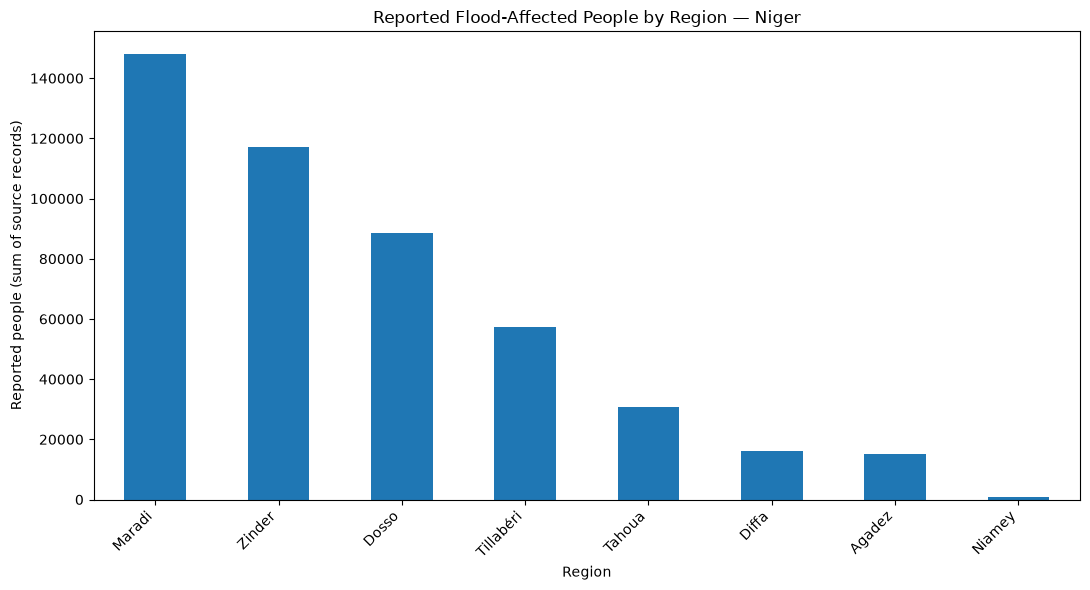

In [40]:
# Aggregate reported affected people by region
people_by_region = (
    df.groupby("Région", dropna=False)["Personnes sinistrées"]
      .sum(min_count=1)
      .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(11, 6))
people_by_region.plot(kind="bar")

plt.title("Reported Flood-Affected People by Region — Niger")
plt.xlabel("Region")
plt.ylabel("Reported people (sum of source records)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

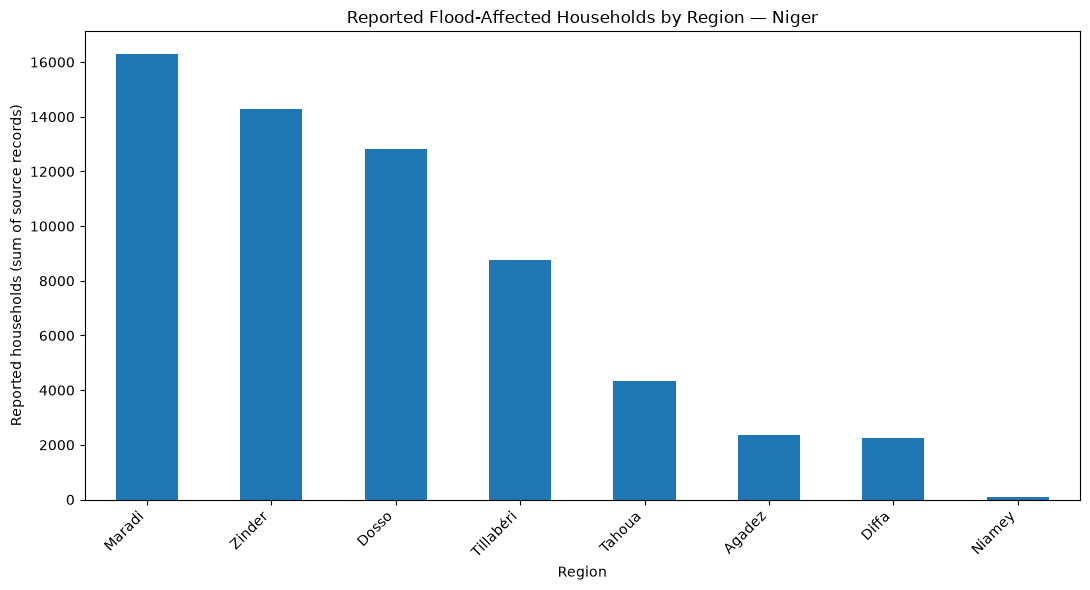

In [42]:
households_by_region = (
    df.groupby("Région", dropna=False)["Ménages sinistrés"]
      .sum(min_count=1)
      .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))
households_by_region.plot(kind="bar")

plt.title("Reported Flood-Affected Households by Region — Niger")
plt.xlabel("Region")
plt.ylabel("Reported households (sum of source records)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [43]:
households_summary = (
    df.groupby("Région")["Ménages sinistrés"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

households_summary.columns = [
    "Région",
    "Ménages sinistrés (somme des lignes)"
]

display(households_summary)

,Région,Ménages sinistrés (somme des lignes)
0,Maradi,16309
1,Zinder,14266
2,Dosso,12803
3,Tillabéri,8763
4,Tahoua,4327
5,Agadez,2366
6,Diffa,2240
7,Niamey,106


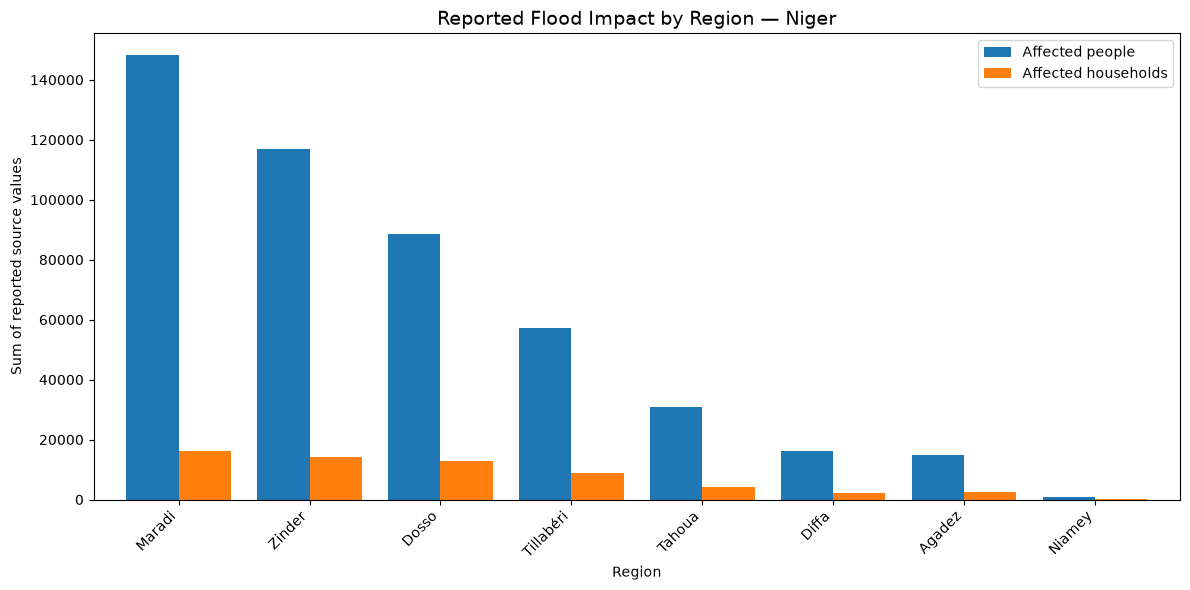

In [44]:
# Aggregate both indicators by region
regional_comparison = (
    df.groupby("Région")[
        ["Personnes sinistrées", "Ménages sinistrés"]
    ]
    .sum()
    .sort_values("Personnes sinistrées", ascending=False)
)

# Create a grouped bar chart
regional_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title(
    "Reported Flood Impact by Region — Niger",
    fontsize=14
)
plt.xlabel("Region")
plt.ylabel("Sum of reported source values")
plt.xticks(rotation=45, ha="right")
plt.legend([
    "Affected people",
    "Affected households"
])
plt.tight_layout()
plt.show()

In [46]:
# Step 5.1 — Investigate repeated department records

In [47]:
# STEP 5.1: Identify repeated department codes

repeated_departments = (
    df.groupby(
        ["Région", "Département", "Pcode2"],
        dropna=False
    )
    .size()
    .reset_index(name="Record_Count")
)

repeated_departments = repeated_departments[
    repeated_departments["Record_Count"] > 1
].sort_values("Record_Count", ascending=False)

if repeated_departments.empty:
    print("No repeated department-code combinations found.")
else:
    print("Repeated department-code combinations:")
    display(repeated_departments)

Repeated department-code combinations:


,Région,Département,Pcode2,Record_Count
4,Agadez,Ingall,NER001005,2
28,Tahoua,Abalak,NER005001,2
32,Tahoua,Keita,NER005006,2
33,Tahoua,Madaoua,NER005007,2
54,Zinder,Takeita,NER007008,2


In [48]:
# STEP 5.2: Inspect all rows for repeated department codes

if not repeated_departments.empty:
    repeated_codes = repeated_departments["Pcode2"].dropna().unique()

    repeated_rows = df[df["Pcode2"].isin(repeated_codes)].sort_values(
        ["Région", "Département", "Pcode2"]
    )

    display(repeated_rows)
else:
    print("No repeated codes to inspect.")

,ISO3,Pcode1,Région,Pcode2,Département,Ménages sinistrés,Personnes sinistrées,Maisons effondrées,Cases endommagées,Pertes en vie humaine par Noyade,...,Greniers,Vivre (Tonne),Puits effondrés,Puits ensevelis,Forages endommagés,Lieu de culte,Centre de santé,Classe,Route,pont endommagé
4,NER,NE001,Agadez,NER001005,Ingall,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0
5,NER,NE001,Agadez,NER001005,Ingall,35,320,8,0,0,...,0,0,0,0,0,0,0,0,0.0,0
29,NER,NE005,Tahoua,NER005001,Abalak,349,2621,346,0,0,...,0,0,0,0,0,0,0,1,0.0,0
30,NER,NE005,Tahoua,NER005001,Abalak,1,6,1,0,0,...,0,0,0,0,0,0,0,0,0.0,0
34,NER,NE005,Tahoua,NER005006,Keita,245,1500,244,0,0,...,0,0,0,0,0,0,0,0,0.0,0
35,NER,NE005,Tahoua,NER005006,Keita,87,321,29,0,0,...,0,0,0,0,0,0,0,0,0.0,0
36,NER,NE005,Tahoua,NER005007,Madaoua,1741,14264,2110,0,1,...,0,0,0,0,0,0,1,2,0.0,0
37,NER,NE005,Tahoua,NER005007,Madaoua,2,22,0,0,1,...,0,0,0,0,0,0,0,0,0.0,0
58,NER,NE007,Zinder,NER007008,Takeita,565,3908,12,0,1,...,0,0,0,0,0,0,0,0,0.0,0
59,NER,NE007,Zinder,NER007008,Takeita,578,5067,223,18,2,...,0,0,0,0,0,0,0,0,0.0,0


In [49]:
# STEP 5.2: Inspect repeated department records

repeated_codes = [
    "NER001005",
    "NER005001",
    "NER005006",
    "NER005007",
    "NER007008"
]

repeated_rows = df[
    df["Pcode2"].astype(str).isin(repeated_codes)
].sort_values(["Région", "Département", "Pcode2"])

# Display key impact indicators for comparison
comparison_columns = [
    "Région",
    "Département",
    "Pcode2",
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Aires de cultures inondées  /ha"
]

display(repeated_rows[comparison_columns])

,Région,Département,Pcode2,Ménages sinistrés,Personnes sinistrées,Maisons effondrées,Cases endommagées,Aires de cultures inondées /ha
4,Agadez,Ingall,NER001005,1,0,1,0,0.0
5,Agadez,Ingall,NER001005,35,320,8,0,0.0
29,Tahoua,Abalak,NER005001,349,2621,346,0,0.0
30,Tahoua,Abalak,NER005001,1,6,1,0,0.0
34,Tahoua,Keita,NER005006,245,1500,244,0,0.0
35,Tahoua,Keita,NER005006,87,321,29,0,0.0
36,Tahoua,Madaoua,NER005007,1741,14264,2110,0,0.0
37,Tahoua,Madaoua,NER005007,2,22,0,0,0.0
58,Zinder,Takeita,NER007008,565,3908,12,0,276.0
59,Zinder,Takeita,NER007008,578,5067,223,18,168.5


In [50]:
# STEP 5.3: Distinguish exact duplicates from repeated department codes

# Count rows that are identical across every column
exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Summarize the repeated department records
repeated_summary = (
    repeated_rows.groupby(
        ["Région", "Département", "Pcode2"],
        dropna=False
    )
    .agg(
        Number_of_records=("Pcode2", "size"),
        Reported_households=("Ménages sinistrés", "sum"),
        Reported_people=("Personnes sinistrées", "sum"),
        Reported_houses_collapsed=("Maisons effondrées", "sum")
    )
    .reset_index()
)

display(repeated_summary)

Exact duplicate rows: 0


,Région,Département,Pcode2,Number_of_records,Reported_households,Reported_people,Reported_houses_collapsed
0,Agadez,Ingall,NER001005,2,36,320,9
1,Tahoua,Abalak,NER005001,2,350,2627,347
2,Tahoua,Keita,NER005006,2,332,1821,273
3,Tahoua,Madaoua,NER005007,2,1743,14286,2110
4,Zinder,Takeita,NER007008,2,1143,8975,235


In [51]:
# STEP 5.4: Review all available columns

for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

1. ISO3
2. Pcode1
3. Région
4. Pcode2
5. Département
6. Ménages sinistrés
7. Personnes sinistrées
8. Maisons effondrées
9. Cases endommagées
10. Pertes en vie humaine par Noyade
11. Pertes en vie humaine par Effond
12. Pertes en vie humaine par Foudre
13. Perte d'animaux par Petits ruminants
14. Perte d'animaux par Gros ruminant
15. Aires de cultures inondées  /ha
16. Latrines
17. Mur
18. Hangars
19. Magasins
20. Boutiques
21. Greniers
22. Vivre (Tonne)
23. Puits effondrés
24. Puits ensevelis
25. Forages endommagés
26. Lieu de culte
27. Centre de santé
28. Classe
29. Route
30. pont endommagé


In [52]:
# Step 6 — Build a regional impact summary

In [53]:
# STEP 6.1: Regional impact summary
# These are sums of source rows, not yet validated official totals.

regional_summary = (
    df.groupby("Région", dropna=False)
      .agg(
          Source_records=("Région", "size"),
          Reported_households=("Ménages sinistrés", "sum"),
          Reported_people=("Personnes sinistrées", "sum"),
          Houses_collapsed=("Maisons effondrées", "sum"),
          Damaged_cases=("Cases endommagées", "sum")
      )
      .reset_index()
      .sort_values("Reported_people", ascending=False)
)

display(regional_summary)

,Région,Source_records,Reported_households,Reported_people,Houses_collapsed,Damaged_cases
3,Maradi,9,16309,148168,15987,368
7,Zinder,10,14266,117026,10257,229
2,Dosso,8,12803,88468,8253,908
6,Tillabéri,12,8763,57349,3520,150
5,Tahoua,11,4327,30805,4615,9
1,Diffa,4,2240,16088,1982,152
0,Agadez,7,2366,14993,1722,158
4,Niamey,1,106,837,114,0


In [54]:
# STEP 6.2: Verify arithmetic consistency

indicators_to_check = [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées"
]

for col in indicators_to_check:
    source_total = df[col].sum()
    regional_total = regional_summary[
        col.replace(" ", "_")
    ].sum() if False else None

    print(f"{col}: sum of source rows = {source_total:,}")

Ménages sinistrés: sum of source rows = 61,180
Personnes sinistrées: sum of source rows = 473,734
Maisons effondrées: sum of source rows = 46,450
Cases endommagées: sum of source rows = 1,974


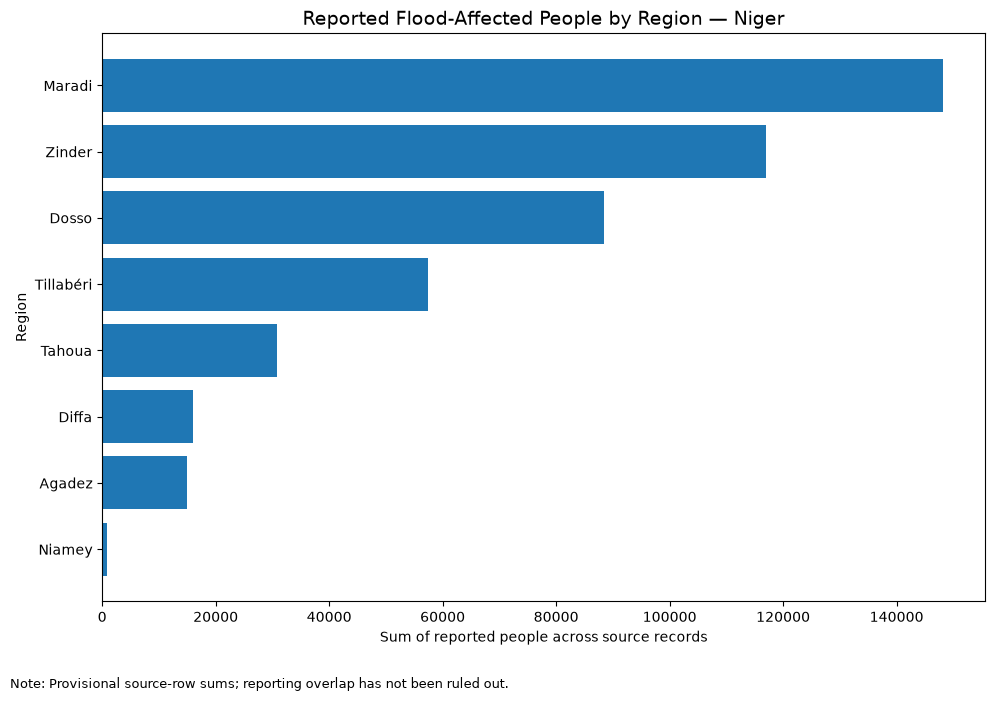

In [55]:
chart_data = regional_summary.sort_values(
    "Reported_people", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    chart_data["Région"],
    chart_data["Reported_people"]
)

plt.title(
    "Reported Flood-Affected People by Region — Niger",
    fontsize=14
)
plt.xlabel("Sum of reported people across source records")
plt.ylabel("Region")
plt.figtext(
    0.01, 0.01,
    "Note: Provisional source-row sums; reporting overlap has not been ruled out.",
    ha="left",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [56]:
# STEP 7.1: Calculate preliminary humanitarian KPIs

kpis = {
    "Reported affected households": df["Ménages sinistrés"].sum(),
    "Reported affected people": df["Personnes sinistrées"].sum(),
    "Reported houses collapsed": df["Maisons effondrées"].sum(),
    "Reported cases damaged": df["Cases endommagées"].sum(),
    "Number of regions": df["Région"].nunique(),
    "Number of source records": len(df)
}

for indicator, value in kpis.items():
    print(f"{indicator}: {value:,}")

Reported affected households: 61,180
Reported affected people: 473,734
Reported houses collapsed: 46,450
Reported cases damaged: 1,974
Number of regions: 8
Number of source records: 62


In [57]:
# STEP 7.2: Preliminary ratio

reported_households = df["Ménages sinistrés"].sum()
reported_people = df["Personnes sinistrées"].sum()

if reported_households > 0:
    people_per_reported_household = (
        reported_people / reported_households
    )
    print(
        "Reported people per reported household:",
        round(people_per_reported_household, 2)
    )
else:
    print("Cannot calculate ratio: household total is zero.")

Reported people per reported household: 7.74


In [58]:
# STEP 7.3: Export provisional regional summary

output_file = "niger_flood_regional_summary_provisional.csv"

regional_summary.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Regional summary saved as:", output_file)

Regional summary saved as: niger_flood_regional_summary_provisional.csv


In [60]:
## Niger flood impact dataset · 29 September 2025
#Reported affected people
# 473,734


# Reported affected households
# 61,180


# Houses collapsed
# 46,450


# Damaged cases
# 1,974

In [61]:
# Step 10.1 — Create a working copy and check data quality

In [62]:

# STEP 10.1: Prepare a clean working dataset

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove whitespace from column names
df_clean.columns = df_clean.columns.str.strip()

# Check dataset dimensions
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

# Check for exact duplicate rows
print(
    "Exact duplicate rows:",
    df_clean.duplicated().sum()
)

# Check missing values
print("\nMissing values by column:")
missing_values = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(missing_values[missing_values > 0])

# Check data types
print("\nColumn data types:")
display(df_clean.dtypes)


Original dataset shape: (62, 30)
Working dataset shape: (62, 30)
Exact duplicate rows: 0

Missing values by column:


Route    1
dtype: int64


Column data types:


ISO3                                        str
Pcode1                                      str
Région                                      str
Pcode2                                      str
Département                                 str
Ménages sinistrés                         int64
Personnes sinistrées                      int64
Maisons effondrées                        int64
Cases endommagées                         int64
Pertes en vie humaine par Noyade          int64
Pertes en vie humaine par Effond          int64
Pertes en vie humaine par Foudre          int64
Perte d'animaux par Petits ruminants      int64
Perte d'animaux par Gros ruminant         int64
Aires de cultures inondées  /ha         float64
Latrines                                  int64
Mur                                       int64
Hangars                                   int64
Magasins                                  int64
Boutiques                                 int64
Greniers                                

In [63]:

# STEP 10.2: Validate key impact indicators

key_indicators = [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées"
]

for column in key_indicators:
    print(f"\n{column}")
    print("Data type:", df_clean[column].dtype)
    print("Missing values:", df_clean[column].isna().sum())
    print("Negative values:", (df_clean[column] < 0).sum())
    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())



Ménages sinistrés
Data type: int64
Missing values: 0
Negative values: 0
Minimum: 1
Maximum: 8474

Personnes sinistrées
Data type: int64
Missing values: 0
Negative values: 0
Minimum: 0
Maximum: 88107

Maisons effondrées
Data type: int64
Missing values: 0
Negative values: 0
Minimum: 0
Maximum: 8023

Cases endommagées
Data type: int64
Missing values: 0
Negative values: 0
Minimum: 0
Maximum: 571


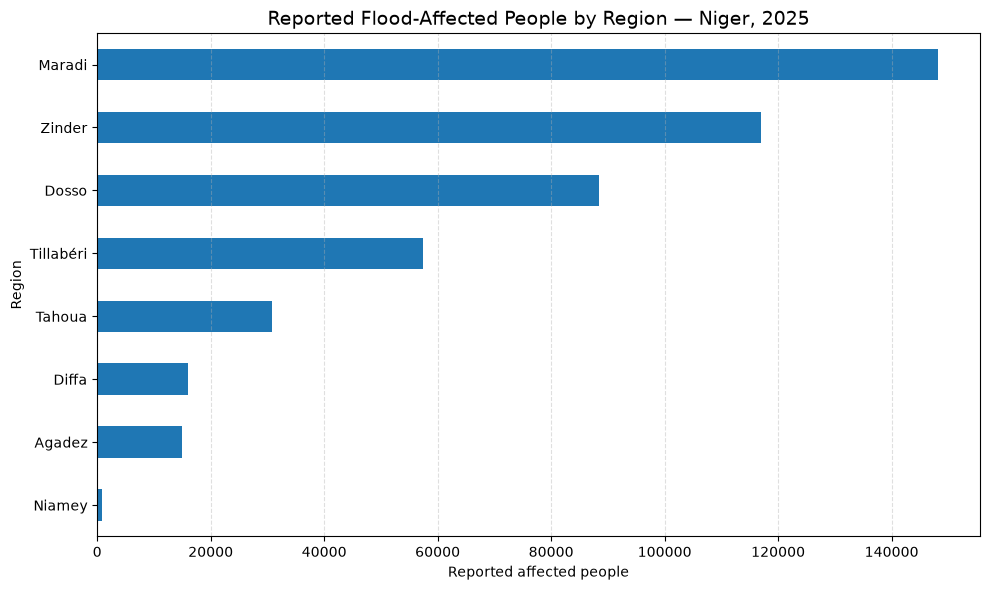

In [64]:
people_by_region = (
    df_clean.groupby("Région", dropna=False)["Personnes sinistrées"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

people_by_region.plot(kind="barh")

plt.title(
    "Reported Flood-Affected People by Region — Niger, 2025",
    fontsize=14
)
plt.xlabel("Reported affected people")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "niger_flood_affected_people_by_region.png",
    dpi=300,
    bbox_inches="tight"
)


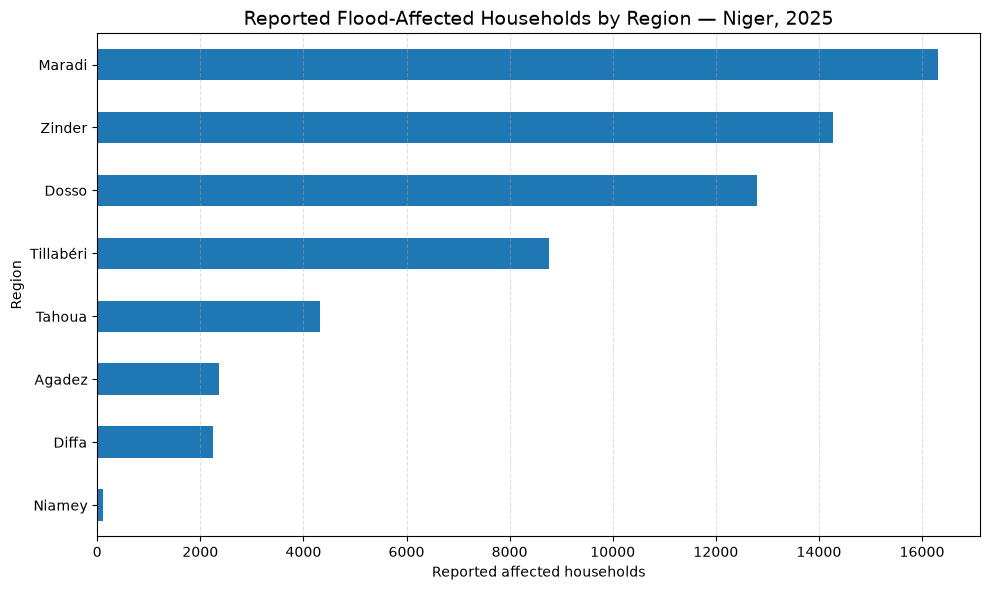

In [65]:

# STEP 11.2: Reported affected households by region

households_by_region = (
    df_clean.groupby("Région", dropna=False)["Ménages sinistrés"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

households_by_region.plot(kind="barh")

plt.title(
    "Reported Flood-Affected Households by Region — Niger, 2025",
    fontsize=14
)
plt.xlabel("Reported affected households")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "niger_flood_affected_households_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


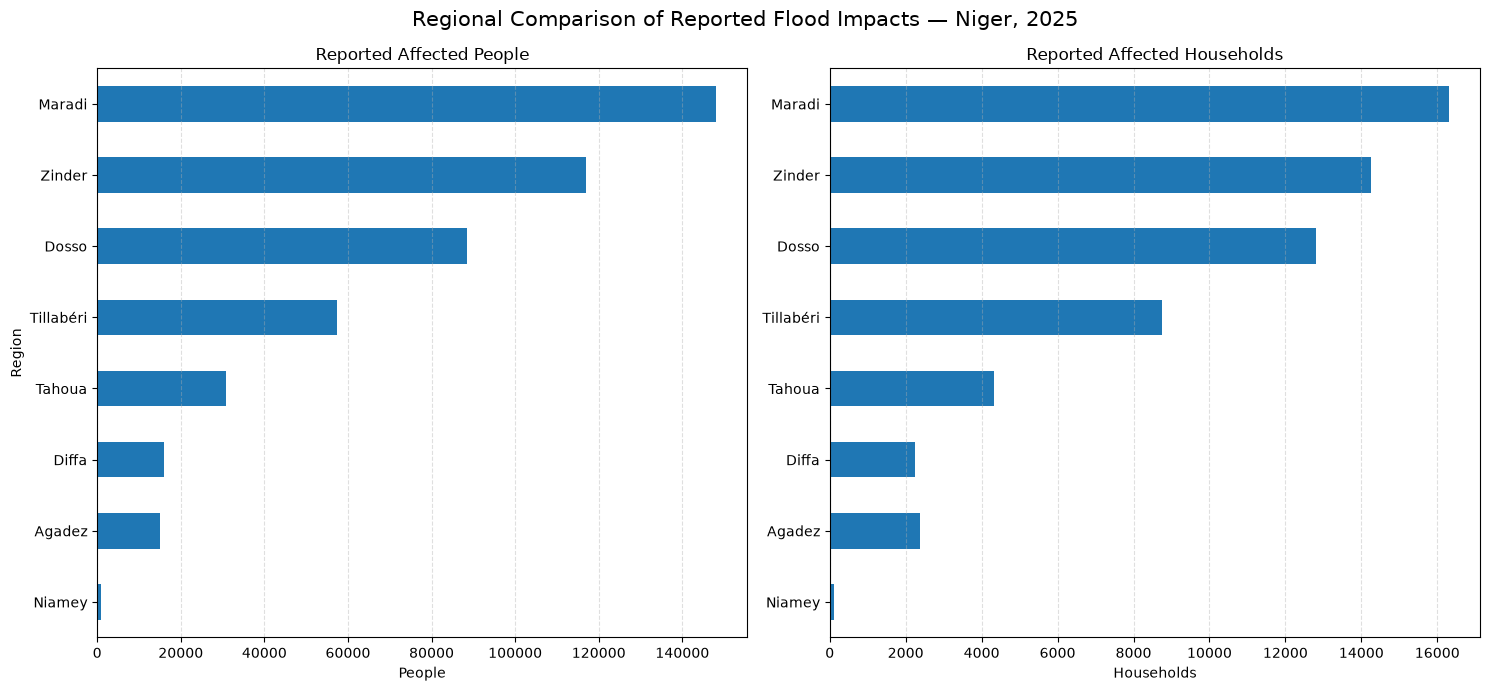

In [66]:

# STEP 11.3: Side-by-side comparison

regional_comparison = (
    df_clean.groupby("Région", dropna=False)
    .agg(
        Reported_people=("Personnes sinistrées", "sum"),
        Reported_households=("Ménages sinistrés", "sum")
    )
    .sort_values("Reported_people", ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

regional_comparison["Reported_people"].plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Reported Affected People")
axes[0].set_xlabel("People")
axes[0].set_ylabel("Region")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

regional_comparison["Reported_households"].plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Reported Affected Households")
axes[1].set_xlabel("Households")
axes[1].set_ylabel("")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

fig.suptitle(
    "Regional Comparison of Reported Flood Impacts — Niger, 2025",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "niger_flood_regional_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [67]:
# Step 12.1 — Calculate regional percentages

In [68]:

# STEP 12.1: Calculate regional shares of reported flood impacts

regional_shares = (
    df_clean.groupby("Région", dropna=False)
    .agg(
        Reported_people=("Personnes sinistrées", "sum"),
        Reported_households=("Ménages sinistrés", "sum"),
        Houses_collapsed=("Maisons effondrées", "sum"),
        Cases_damaged=("Cases endommagées", "sum")
    )
    .reset_index()
)

# Calculate each region's share of the source-record totals
total_people = regional_shares["Reported_people"].sum()
total_households = regional_shares["Reported_households"].sum()

regional_shares["People_share_pct"] = (
    regional_shares["Reported_people"] / total_people * 100
    if total_people > 0 else 0
)

regional_shares["Households_share_pct"] = (
    regional_shares["Reported_households"] / total_households * 100
    if total_households > 0 else 0
)

# Rank regions by reported affected people
regional_shares = regional_shares.sort_values(
    "Reported_people", ascending=False
)

display(
    regional_shares.round({
        "People_share_pct": 2,
        "Households_share_pct": 2
    })
)


,Région,Reported_people,Reported_households,Houses_collapsed,Cases_damaged,People_share_pct,Households_share_pct
3,Maradi,148168,16309,15987,368,31.28,26.66
7,Zinder,117026,14266,10257,229,24.70,23.32
2,Dosso,88468,12803,8253,908,18.67,20.93
6,Tillabéri,57349,8763,3520,150,12.11,14.32
5,Tahoua,30805,4327,4615,9,6.50,7.07
1,Diffa,16088,2240,1982,152,3.40,3.66
0,Agadez,14993,2366,1722,158,3.16,3.87
4,Niamey,837,106,114,0,0.18,0.17


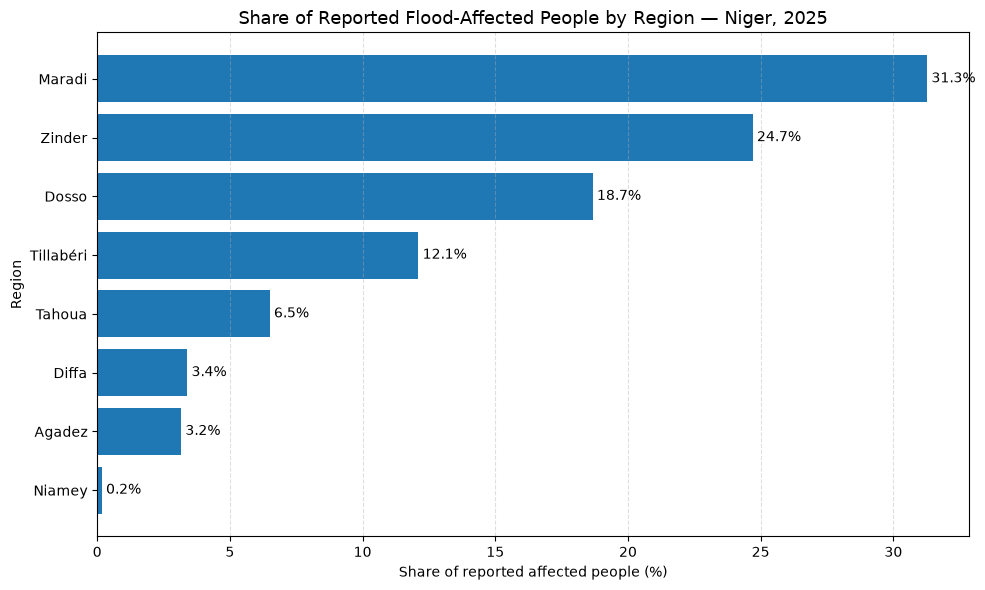

In [69]:

# STEP 12.2: Visualize the share of reported affected people

plot_data = regional_shares.sort_values(
    "People_share_pct", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data["Région"].astype(str),
    plot_data["People_share_pct"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title(
    "Share of Reported Flood-Affected People by Region — Niger, 2025",
    fontsize=13
)
plt.xlabel("Share of reported affected people (%)")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "niger_flood_regional_people_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [70]:

# STEP 12.3: Rank the top three regions

top_three_regions = regional_shares.head(3)[
    [
        "Région",
        "Reported_people",
        "People_share_pct",
        "Reported_households",
        "Households_share_pct"
    ]
].copy()

top_three_regions = top_three_regions.round({
    "People_share_pct": 2,
    "Households_share_pct": 2
})

print("Top 3 regions by reported affected people:")
display(top_three_regions)


Top 3 regions by reported affected people:


,Région,Reported_people,People_share_pct,Reported_households,Households_share_pct
3,Maradi,148168,31.28,16309,26.66
7,Zinder,117026,24.70,14266,23.32
2,Dosso,88468,18.67,12803,20.93


In [71]:

# STEP 13.1: Analyze reported housing damage by region

housing_damage = (
    df_clean.groupby("Région", dropna=False)
    .agg(
        Houses_collapsed=("Maisons effondrées", "sum"),
        Cases_damaged=("Cases endommagées", "sum")
    )
    .reset_index()
)

housing_damage["Total_reported_damage_records"] = (
    housing_damage["Houses_collapsed"]
    + housing_damage["Cases_damaged"]
)

housing_damage = housing_damage.sort_values(
    "Total_reported_damage_records",
    ascending=False
)

display(housing_damage)

print("\nProvisional reported housing-damage totals:")
print(
    "Collapsed houses:",
    housing_damage["Houses_collapsed"].sum()
)
print(
    "Damaged cases:",
    housing_damage["Cases_damaged"].sum()
)


,Région,Houses_collapsed,Cases_damaged,Total_reported_damage_records
3,Maradi,15987,368,16355
7,Zinder,10257,229,10486
2,Dosso,8253,908,9161
5,Tahoua,4615,9,4624
6,Tillabéri,3520,150,3670
1,Diffa,1982,152,2134
0,Agadez,1722,158,1880
4,Niamey,114,0,114



Provisional reported housing-damage totals:
Collapsed houses: 46450
Damaged cases: 1974


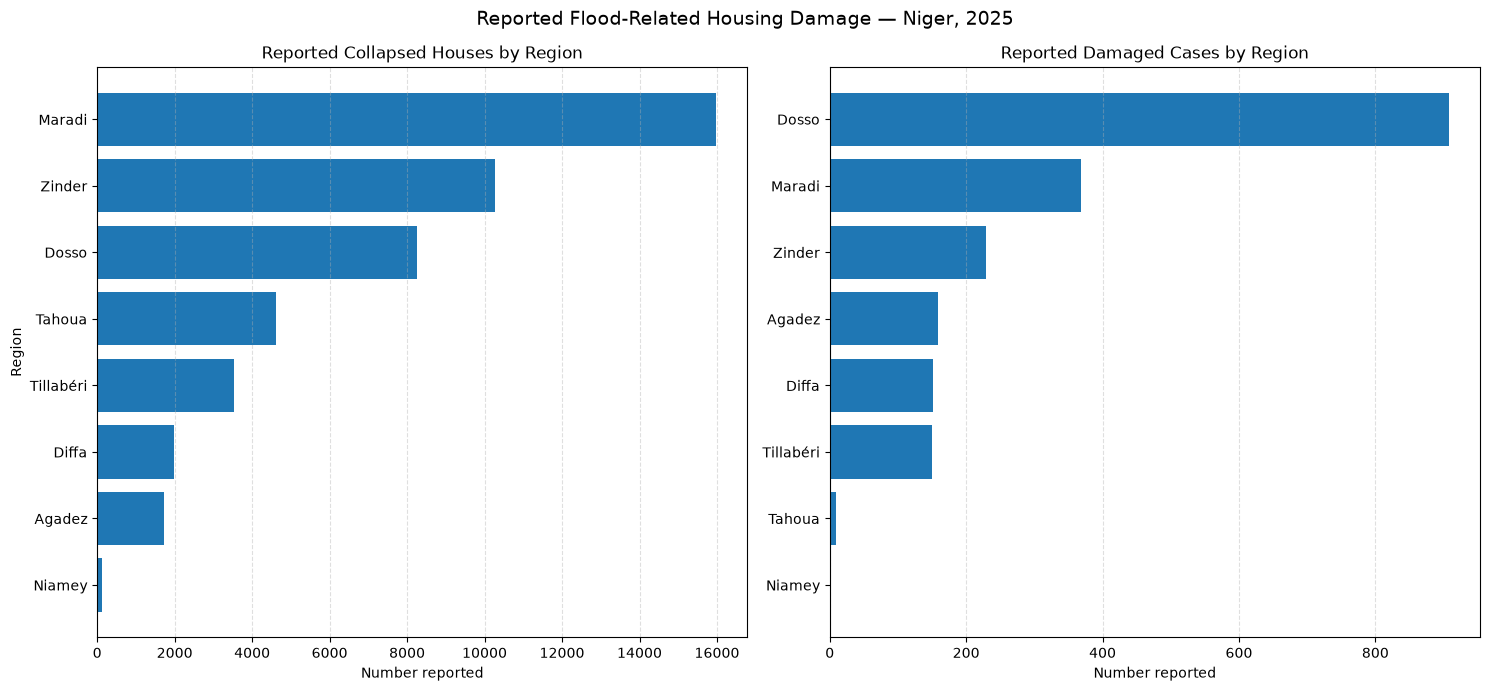

In [72]:

# STEP 13.2: Compare collapsed houses and damaged cases

housing_plot = housing_damage.sort_values(
    "Houses_collapsed", ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(
    housing_plot["Région"].astype(str),
    housing_plot["Houses_collapsed"]
)
axes[0].set_title("Reported Collapsed Houses by Region")
axes[0].set_xlabel("Number reported")
axes[0].set_ylabel("Region")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

cases_plot = housing_damage.sort_values(
    "Cases_damaged", ascending=True
)

axes[1].barh(
    cases_plot["Région"].astype(str),
    cases_plot["Cases_damaged"]
)
axes[1].set_title("Reported Damaged Cases by Region")
axes[1].set_xlabel("Number reported")
axes[1].set_ylabel("")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

fig.suptitle(
    "Reported Flood-Related Housing Damage — Niger, 2025",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "niger_flood_housing_damage_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [73]:

# STEP 13.3: Rank regions by reported collapsed houses

top_housing_damage = housing_damage.sort_values(
    "Houses_collapsed", ascending=False
).head(5)

print("Top 5 regions by reported collapsed houses:")
display(top_housing_damage)

print("\nTop 5 regions by reported damaged cases:")
display(
    housing_damage.sort_values(
        "Cases_damaged", ascending=False
    ).head(5)
)


Top 5 regions by reported collapsed houses:


,Région,Houses_collapsed,Cases_damaged,Total_reported_damage_records
3,Maradi,15987,368,16355
7,Zinder,10257,229,10486
2,Dosso,8253,908,9161
5,Tahoua,4615,9,4624
6,Tillabéri,3520,150,3670



Top 5 regions by reported damaged cases:


,Région,Houses_collapsed,Cases_damaged,Total_reported_damage_records
2,Dosso,8253,908,9161
3,Maradi,15987,368,16355
7,Zinder,10257,229,10486
0,Agadez,1722,158,1880
1,Diffa,1982,152,2134


In [74]:
# identified the relevant columns

In [75]:

# STEP 14.1: Identify columns related to services and livelihoods

for column in df_clean.columns:
    print(column)


ISO3
Pcode1
Région
Pcode2
Département
Ménages sinistrés
Personnes sinistrées
Maisons effondrées
Cases endommagées
Pertes en vie humaine par Noyade
Pertes en vie humaine par Effond
Pertes en vie humaine par Foudre
Perte d'animaux par Petits ruminants
Perte d'animaux par Gros ruminant
Aires de cultures inondées  /ha
Latrines
Mur
Hangars
Magasins
Boutiques
Greniers
Vivre (Tonne)
Puits effondrés
Puits ensevelis
Forages endommagés
Lieu de culte
Centre de santé
Classe
Route
pont endommagé


In [76]:
# summarize reported damages

In [77]:

# STEP 14.2: Summarize reported damage to services and livelihoods

impact_columns = [
    "Latrines",
    "Puits effondrés",
    "Puits ensevelis",
    "Forages endommagés",
    "Centre de santé",
    "Classe",
    "Route",
    "pont endommagé",
    "Aires de cultures inondées  /ha"
]

# Check which requested columns exist
available_columns = [
    col for col in impact_columns
    if col in df_clean.columns
]

missing_columns = [
    col for col in impact_columns
    if col not in df_clean.columns
]

print("Available indicators:", available_columns)
print("Columns not found:", missing_columns)

# Convert selected indicators to numeric for analysis
impact_data = df_clean[available_columns].copy()

for col in available_columns:
    impact_data[col] = pd.to_numeric(
        impact_data[col], errors="coerce"
    )

# Summarize each indicator
impact_summary = pd.DataFrame({
    "Indicator": available_columns,
    "Records_with_values": [
        impact_data[col].count() for col in available_columns
    ],
    "Missing_records": [
        impact_data[col].isna().sum() for col in available_columns
    ],
    "Reported_sum": [
        impact_data[col].sum(min_count=1)
        for col in available_columns
    ]
})

display(impact_summary)


Available indicators: ['Latrines', 'Puits effondrés', 'Puits ensevelis', 'Forages endommagés', 'Centre de santé', 'Classe', 'Route', 'pont endommagé', 'Aires de cultures inondées  /ha']
Columns not found: []


,Indicator,Records_with_values,Missing_records,Reported_sum
0,Latrines,62,0,186.00
1,Puits effondrés,62,0,6.00
2,Puits ensevelis,62,0,18.00
3,Forages endommagés,62,0,0.00
4,Centre de santé,62,0,3.00
5,Classe,62,0,40.00
6,Route,61,1,0.00
7,pont endommagé,62,0,0.00
8,Aires de cultures inondées /ha,62,0,8876.93


In [78]:
# Visualize reported impact 

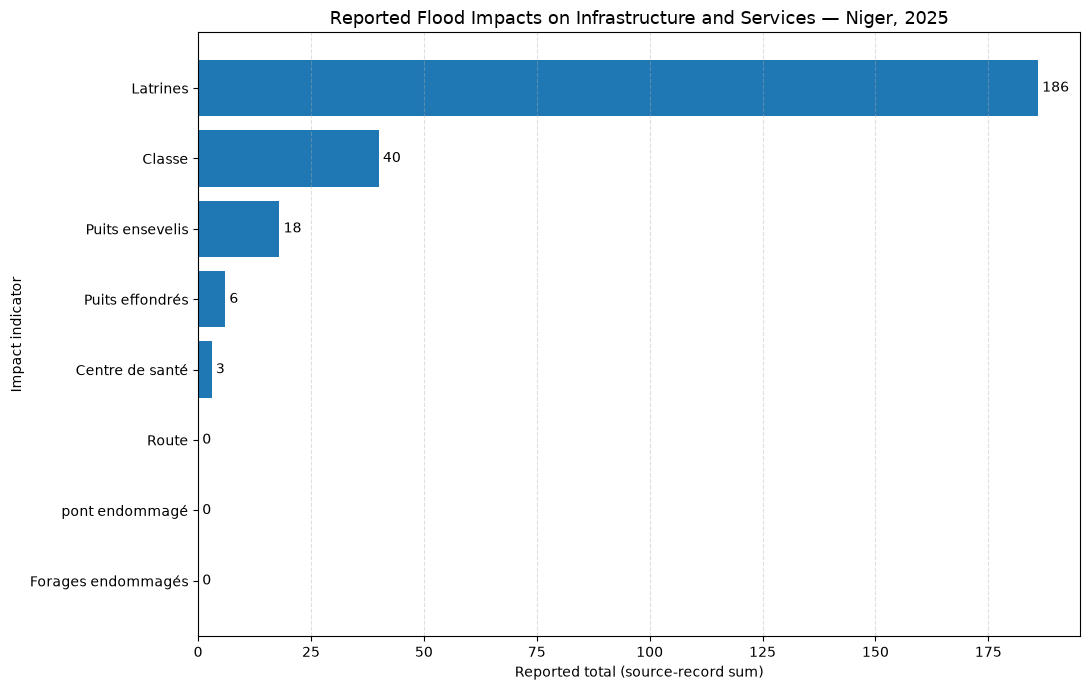

In [79]:

# STEP 14.3: Plot reported infrastructure and service impacts

chart_columns = [
    col for col in available_columns
    if col != "Aires de cultures inondées  /ha"
]

chart_data = impact_summary[
    impact_summary["Indicator"].isin(chart_columns)
].dropna(subset=["Reported_sum"])

chart_data = chart_data.sort_values(
    "Reported_sum", ascending=True
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    chart_data["Indicator"],
    chart_data["Reported_sum"]
)

plt.bar_label(bars, padding=3, fmt="%.0f")

plt.title(
    "Reported Flood Impacts on Infrastructure and Services — Niger, 2025",
    fontsize=13
)
plt.xlabel("Reported total (source-record sum)")
plt.ylabel("Impact indicator")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "niger_flood_infrastructure_service_impacts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [80]:
# Analyse Flood and agriculture and land

In [81]:

# STEP 14.4: Analyze reported flooded agricultural land

agri_column = "Aires de cultures inondées  /ha"

if agri_column in df_clean.columns:
    agricultural_land = pd.to_numeric(
        df_clean[agri_column], errors="coerce"
    )

    print(
        "Records with agricultural land data:",
        agricultural_land.count()
    )
    print(
        "Missing agricultural land records:",
        agricultural_land.isna().sum()
    )
    print(
        "Reported flooded agricultural land (ha):",
        agricultural_land.sum(min_count=1)
    )
else:
    print("Agricultural land column not found. Check Step 14.1.")


Records with agricultural land data: 62
Missing agricultural land records: 0
Reported flooded agricultural land (ha): 8876.93


In [82]:
# Creating a regional Dashbord

In [83]:
dashboard_columns = [
    "Ménages sinistrés",
    "Personnes sinistrées",
    "Maisons effondrées",
    "Cases endommagées",
    "Latrines",
    "Puits effondrés",
    "Puits ensevelis",
    "Forages endommagés",
    "Centre de santé",
    "Classe",
    "Route",
    "pont endommagé",
    "Aires de cultures inondées  /ha"
]

# Keep only indicators that exist in the dataset
available_dashboard_columns = [
    col for col in dashboard_columns
    if col in df_clean.columns
]

# Convert indicators to numeric without replacing missing values with zero
for col in available_dashboard_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Aggregate by region
regional_dashboard = (
    df_clean.groupby("Région", dropna=False)
    .agg(
        Source_records=("Région", "size"),
        Reported_households=("Ménages sinistrés", "sum"),
        Reported_people=("Personnes sinistrées", "sum"),
        Houses_collapsed=("Maisons effondrées", "sum"),
        Cases_damaged=("Cases endommagées", "sum"),
        Latrines=("Latrines", "sum"),
        Wells_collapsed=("Puits effondrés", "sum"),
        Wells_buried=("Puits ensevelis", "sum"),
        Boreholes_damaged=("Forages endommagés", "sum"),
        Health_centers=("Centre de santé", "sum"),
        Classrooms=("Classe", "sum"),
        Roads=("Route", "sum"),
        Bridges_damaged=("pont endommagé", "sum"),
        Flooded_agricultural_land_ha=(
            "Aires de cultures inondées  /ha", "sum"
        )
    )
    .reset_index()
    .sort_values("Reported_people", ascending=False)
)

display(regional_dashboard.round(2))

,Région,Source_records,Reported_households,Reported_people,Houses_collapsed,Cases_damaged,Latrines,Wells_collapsed,Wells_buried,Boreholes_damaged,Health_centers,Classrooms,Roads,Bridges_damaged,Flooded_agricultural_land_ha
3,Maradi,9,16309,148168,15987,368,0,0,0,0,0,3,0.0,0,2945.50
7,Zinder,10,14266,117026,10257,229,4,2,4,0,2,8,0.0,0,3244.58
2,Dosso,8,12803,88468,8253,908,21,0,0,0,0,0,0.0,0,1556.50
6,Tillabéri,12,8763,57349,3520,150,50,0,0,0,0,26,0.0,0,1031.10
5,Tahoua,11,4327,30805,4615,9,5,0,0,0,1,3,0.0,0,0.00
1,Diffa,4,2240,16088,1982,152,89,0,0,0,0,0,0.0,0,33.25
0,Agadez,7,2366,14993,1722,158,17,4,14,0,0,0,0.0,0,66.00
4,Niamey,1,106,837,114,0,0,0,0,0,0,0,0.0,0,0.00


In [84]:

# STEP 15.2: Count repeated department codes by region

repeated_code_rows = df_clean[
    df_clean.duplicated(subset=["Pcode2"], keep=False)
]

repeated_codes_by_region = (
    repeated_code_rows.groupby("Région", dropna=False)
    .size()
    .rename("Rows_with_repeated_department_code")
    .reset_index()
)

regional_dashboard = regional_dashboard.merge(
    repeated_codes_by_region,
    on="Région",
    how="left"
)

regional_dashboard["Rows_with_repeated_department_code"] = (
    regional_dashboard["Rows_with_repeated_department_code"]
    .fillna(0)
    .astype(int)
)

print("Updated regional dashboard:")
display(regional_dashboard)


Updated regional dashboard:


,Région,Source_records,Reported_households,Reported_people,Houses_collapsed,Cases_damaged,Latrines,Wells_collapsed,Wells_buried,Boreholes_damaged,Health_centers,Classrooms,Roads,Bridges_damaged,Flooded_agricultural_land_ha,Rows_with_repeated_department_code
0,Maradi,9,16309,148168,15987,368,0,0,0,0,0,3,0.0,0,2945.50,0
1,Zinder,10,14266,117026,10257,229,4,2,4,0,2,8,0.0,0,3244.58,2
2,Dosso,8,12803,88468,8253,908,21,0,0,0,0,0,0.0,0,1556.50,0
3,Tillabéri,12,8763,57349,3520,150,50,0,0,0,0,26,0.0,0,1031.10,0
4,Tahoua,11,4327,30805,4615,9,5,0,0,0,1,3,0.0,0,0.00,6
5,Diffa,4,2240,16088,1982,152,89,0,0,0,0,0,0.0,0,33.25,0
6,Agadez,7,2366,14993,1722,158,17,4,14,0,0,0,0.0,0,66.00,2
7,Niamey,1,106,837,114,0,0,0,0,0,0,0,0.0,0,0.00,0


In [85]:

# STEP 15.3: Export regional dashboard dataset

output_file = "niger_flood_regional_dashboard_provisional.csv"

regional_dashboard.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Dashboard dataset exported successfully.")
print("Filename:", output_file)
print("Number of regional rows:", len(regional_dashboard))
print("Number of columns:", len(regional_dashboard.columns))


Dashboard dataset exported successfully.
Filename: niger_flood_regional_dashboard_provisional.csv
Number of regional rows: 8
Number of columns: 16


In [86]:
# create a power bi export

In [87]:

# STEP 16.1: Prepare a Power BI-ready dataset

powerbi_data = regional_dashboard.copy()

# Rename columns for clarity in Power BI
powerbi_data = powerbi_data.rename(columns={
    "Région": "Region",
    "Source_records": "Source_Records",
    "Reported_households": "Reported_Affected_Households",
    "Reported_people": "Reported_Affected_People",
    "Houses_collapsed": "Reported_Collapsed_Houses",
    "Cases_damaged": "Reported_Damaged_Cases",
    "Latrines": "Reported_Damaged_Latrines",
    "Wells_collapsed": "Reported_Collapsed_Wells",
    "Wells_buried": "Reported_Buried_Wells",
    "Boreholes_damaged": "Reported_Damaged_Boreholes",
    "Health_centers": "Reported_Affected_Health_Centers",
    "Classrooms": "Reported_Affected_Classrooms",
    "Roads": "Reported_Road_Impacts",
    "Bridges_damaged": "Reported_Damaged_Bridges",
    "Flooded_agricultural_land_ha": "Reported_Flooded_Agricultural_Land_Ha",
    "Rows_with_repeated_department_code": "Rows_With_Repeated_Department_Code"
})

print("Power BI dataset shape:", powerbi_data.shape)
display(powerbi_data.head())


Power BI dataset shape: (8, 16)


,Region,Source_Records,Reported_Affected_Households,Reported_Affected_People,Reported_Collapsed_Houses,Reported_Damaged_Cases,Reported_Damaged_Latrines,Reported_Collapsed_Wells,Reported_Buried_Wells,Reported_Damaged_Boreholes,Reported_Affected_Health_Centers,Reported_Affected_Classrooms,Reported_Road_Impacts,Reported_Damaged_Bridges,Reported_Flooded_Agricultural_Land_Ha,Rows_With_Repeated_Department_Code
0,Maradi,9,16309,148168,15987,368,0,0,0,0,0,3,0.0,0,2945.50,0
1,Zinder,10,14266,117026,10257,229,4,2,4,0,2,8,0.0,0,3244.58,2
2,Dosso,8,12803,88468,8253,908,21,0,0,0,0,0,0.0,0,1556.50,0
3,Tillabéri,12,8763,57349,3520,150,50,0,0,0,0,26,0.0,0,1031.10,0
4,Tahoua,11,4327,30805,4615,9,5,0,0,0,1,3,0.0,0,0.00,6


In [88]:

# STEP 16.2: Calculate analytical indicators

# Copy the dataset to keep the exported base table unchanged
powerbi_analysis = powerbi_data.copy()

# Percentage of reported people relative to reported households
# This is a diagnostic ratio, not a validated household-size estimate.
powerbi_analysis["Reported_People_Per_Household_Ratio"] = (
    powerbi_analysis["Reported_Affected_People"]
    / powerbi_analysis["Reported_Affected_Households"].where(
        powerbi_analysis["Reported_Affected_Households"] != 0
    )
)

# Collapsed houses per 1,000 reported affected people
powerbi_analysis["Collapsed_Houses_Per_1000_Reported_People"] = (
    powerbi_analysis["Reported_Collapsed_Houses"]
    / powerbi_analysis["Reported_Affected_People"].where(
        powerbi_analysis["Reported_Affected_People"] != 0
    ) * 1000
)

# Check the calculated indicators
display(
    powerbi_analysis[
        [
            "Region",
            "Reported_Affected_Households",
            "Reported_Affected_People",
            "Reported_Collapsed_Houses",
            "Reported_People_Per_Household_Ratio",
            "Collapsed_Houses_Per_1000_Reported_People"
        ]
    ].round(2)
)


,Region,Reported_Affected_Households,Reported_Affected_People,Reported_Collapsed_Houses,Reported_People_Per_Household_Ratio,Collapsed_Houses_Per_1000_Reported_People
0,Maradi,16309,148168,15987,9.09,107.90
1,Zinder,14266,117026,10257,8.20,87.65
2,Dosso,12803,88468,8253,6.91,93.29
3,Tillabéri,8763,57349,3520,6.54,61.38
4,Tahoua,4327,30805,4615,7.12,149.81
5,Diffa,2240,16088,1982,7.18,123.20
6,Agadez,2366,14993,1722,6.34,114.85
7,Niamey,106,837,114,7.90,136.20


In [89]:

# STEP 16.3: Export the analytical dataset for Power BI

powerbi_file = "niger_flood_powerbi_dataset_provisional.csv"

powerbi_analysis.to_csv(
    powerbi_file,
    index=False,
    encoding="utf-8-sig"
)

print("Power BI export created:", powerbi_file)
print("Rows:", len(powerbi_analysis))
print("Columns:", len(powerbi_analysis.columns))


Power BI export created: niger_flood_powerbi_dataset_provisional.csv
Rows: 8
Columns: 18
